# GRU generation carport




In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import time
# Gebruik de GPU als die er is, anders de CPU
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", DEVICE)

Device: cuda


# Data inladen

In [2]:
df= pd.read_parquet('../../prepared_data/forecast_targets_long.parquet')
carport_generation = df[(df['location'] == 'carport') & (df['target_type'] == 'generation')]
carport_generation = carport_generation.dropna(subset=['pow_imputed'])

## voorspel instellingen

In [3]:
stap_per_dag = 24 * 12               # 288 per dag

aantal_dagen_input = 7               # aantal dagen voor input
input_len = aantal_dagen_input * stap_per_dag

aantal_dagen_forecast = 3            # =aantal dagen voorspelling
horizon = aantal_dagen_forecast * stap_per_dag

stride = 12                          # het venster schuift 12 stappen (1 uur) per voorbeeld op

TIME_COL = 'timestamp'   # pas aan naar de naam van jouw tijdkolom (of gebruik de index, zie onder)
tijd = pd.to_datetime(carport_generation[TIME_COL])
uur = tijd.dt.hour                                   # 0 t/m 23
dag_van_week = tijd.dt.dayofweek + uur / 24          # 0.0 t/m 6.96

carport_generation['uur_sin']  = np.sin(2 * np.pi * uur / 24)
carport_generation['uur_cos']  = np.cos(2 * np.pi * uur / 24)
carport_generation['week_sin'] = np.sin(2 * np.pi * dag_van_week / 7)
carport_generation['week_cos'] = np.cos(2 * np.pi * dag_van_week / 7)
TARGET_COL = 'pow_imputed'
FEATURE_COLS = ['pow_imputed', 'uur_sin', 'uur_cos', 'week_sin', 'week_cos']   # target blijft op index 0                  # features (inclusief target)


TRAIN_FRAC = 0.70                    # deel van de data voor training
VAL_FRAC = 0.15                      # deel voor validatie data  ,de rest is test data

In [4]:
n_features = len(FEATURE_COLS)
target_idx = FEATURE_COLS.index(TARGET_COL)

## chronologisch splisen

In [5]:
values = carport_generation[FEATURE_COLS].values

n = len(values)
i_train = int(n * TRAIN_FRAC)
i_val = int(n * (TRAIN_FRAC + VAL_FRAC))

train_raw = values[:i_train]
val_raw = values[i_train:i_val]
test_raw = values[i_val:]

## normaliseren

In [6]:
train_mean = train_raw.mean(axis=0)
train_std = train_raw.std(axis=0)

train = (train_raw - train_mean) / train_std
val = (val_raw - train_mean) / train_std
test = (test_raw - train_mean) / train_std

In [7]:
class WindowDataset(Dataset):

    def __init__(self, data, input_len, horizon, target_idx, stride):
        self.data = torch.tensor(data, dtype=torch.float32)
        self.input_len = input_len
        self.horizon = horizon
        self.target_idx = target_idx

        # Hoeveel vensters passen er in de data? Elk venster heeft input_len + horizon stappen nodig
        n_vensters = len(data) - input_len - horizon + 1
        self.starts = range(0, max(n_vensters, 0), stride)

    # Bereken het aantal voorbeelden
    def __len__(self):
        return len(self.starts)

    # Haal voorbeeld nummer idx op
    def __getitem__(self, idx):
        s = self.starts[idx]
        x = self.data[s : s + self.input_len]                                   # geschiedenis
        y = self.data[s + self.input_len : s + self.input_len + self.horizon,   # toekomst,
                      self.target_idx]                                          # alleen de target
        return x, y

Creeer dataset voor de training, validatie en test data.

In [8]:
train_dataset = WindowDataset(train, input_len, horizon, target_idx, stride)
val_dataset = WindowDataset(val, input_len, horizon, target_idx, stride)
test_dataset = WindowDataset(test, input_len, horizon, target_idx, stride)

print("aantal voorbeelden | train:", len(train_dataset), "| val:", len(val_dataset), "| test:", len(test_dataset))

aantal voorbeelden | train: 12210 | val: 2428 | test: 2428


Creeer DataLoader 

In [9]:
batch_size = 32

train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=batch_size)
test_loader = DataLoader(test_dataset, batch_size=batch_size)

## model

In [10]:
class RNNModel(nn.Module):
    def __init__(self, input_size, hidden_size, num_layers, output_size, dropout):
        super(RNNModel, self).__init__()
        #gru
        self.rnn = nn.GRU(input_size, hidden_size, num_layers, batch_first=True,
                              dropout=dropout if num_layers > 1 else 0.0)

        # Van de uitvoer van de laatste stap naar de voorspelling
        self.fc = nn.Linear(hidden_size, output_size)

    def forward(self, x):
        # x heeft de vorm (batch, tijd, features)
        out, _ = self.rnn(x)          # uitvoer bij elke tijdstap: (batch, tijd, hidden_size)
        out = out[:, -1, :]           # alleen de laatste tijdstap: (batch, hidden_size)
        return self.fc(out)           # voorspelling: (batch, horizon)

## training loop


In [ ]:
hidden_sizes = [64]            # het aantal getallen van hidden size staat gelijk aan het aantal lagen 
dropout = 0.2                  
learning_rate = 1e-3
output_size = horizon           

class Customgru(nn.Module):
    def __init__(self, input_size, hidden_sizes, output_size, dropout=0.0):
        super().__init__()

        self.layers = nn.ModuleList()
        self.dropout = nn.Dropout(dropout)

        prev_size = input_size
        for h in hidden_sizes:
            self.layers.append(
                nn.GRU(input_size=prev_size,
                        hidden_size=h,
                        num_layers=1,
                        batch_first=True)
            )
            prev_size = h

        self.fc = nn.Linear(hidden_sizes[-1], output_size)

    def forward(self, x):
        out = x
        for lstm in self.layers:
            out, _ = lstm(out)
            out = self.dropout(out)

        out = out[:, -1, :]
        return self.fc(out)

model = Customgru(
    input_size=n_features,
    hidden_sizes=hidden_sizes,
    output_size=horizon,
    dropout=0.2
).to(DEVICE)

criterion = nn.L1Loss()
optimizer = optim.Adam(model.parameters(), lr=learning_rate)

print("CUSTOM gru |", sum(p.numel() for p in model.parameters()), "parameters")


CUSTOM gru | 56412 parameters


In [12]:
n_epochs = 20

train_loss_list = []
val_loss_list = []
epoch_time_list = []                                 

if DEVICE == "cuda":                                  
    torch.cuda.synchronize()
start_totaal = time.perf_counter()                   #start tijd

for epoch in range(n_epochs):
    start_epoch = time.perf_counter()                 
    # Trainen
    model.train()
    running_loss = 0.0

    for inputs, targets in train_loader:
        inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)

        optimizer.zero_grad()
        output = model(inputs)
        loss = criterion(output, targets)
        loss.backward()
        optimizer.step()

        running_loss += loss.item() * targets.shape[0]

    train_loss = running_loss / len(train_dataset)
    train_loss_list.append(train_loss)

    # Validatie
    model.eval()
    val_loss = 0.0
    with torch.no_grad():
        for inputs, targets in val_loader:
            inputs, targets = inputs.to(DEVICE), targets.to(DEVICE)
            loss = criterion(model(inputs), targets)
            val_loss += loss.item() * targets.shape[0]
    val_loss = val_loss / len(val_dataset)
    val_loss_list.append(val_loss)

    if DEVICE == "cuda":                              
        torch.cuda.synchronize()
    epoch_tijd = time.perf_counter() - start_epoch   # epoch train tijd berekenen
    epoch_time_list.append(epoch_tijd)                

    print(f"Epoch {epoch+1}/{n_epochs}, train loss: {train_loss:.4f}, "
          f"validation loss: {val_loss:.4f}, tijd: {epoch_tijd:.1f}s")

totale_tijd = time.perf_counter() - start_totaal  # totale tijd berekenen
print(f"\nTotale trainingstijd: {totale_tijd:.1f}s ({totale_tijd/60:.1f} min)")
print(f"Gemiddeld per epoch: {np.mean(epoch_time_list):.1f}s")

Epoch 1/20, train loss: 0.5007, validation loss: 0.1834, tijd: 4.5s
Epoch 2/20, train loss: 0.3710, validation loss: 0.1325, tijd: 4.3s
Epoch 3/20, train loss: 0.3523, validation loss: 0.1301, tijd: 4.3s
Epoch 4/20, train loss: 0.3459, validation loss: 0.1263, tijd: 4.3s
Epoch 5/20, train loss: 0.3401, validation loss: 0.1240, tijd: 4.3s
Epoch 6/20, train loss: 0.3370, validation loss: 0.1255, tijd: 4.3s
Epoch 7/20, train loss: 0.3331, validation loss: 0.1257, tijd: 4.3s
Epoch 8/20, train loss: 0.3293, validation loss: 0.1232, tijd: 4.3s
Epoch 9/20, train loss: 0.3268, validation loss: 0.1253, tijd: 4.4s
Epoch 10/20, train loss: 0.3246, validation loss: 0.1223, tijd: 4.3s
Epoch 11/20, train loss: 0.3218, validation loss: 0.1330, tijd: 4.3s
Epoch 12/20, train loss: 0.3195, validation loss: 0.1198, tijd: 4.4s
Epoch 13/20, train loss: 0.3172, validation loss: 0.1249, tijd: 4.4s
Epoch 14/20, train loss: 0.3166, validation loss: 0.1185, tijd: 4.3s
Epoch 15/20, train loss: 0.3149, validation

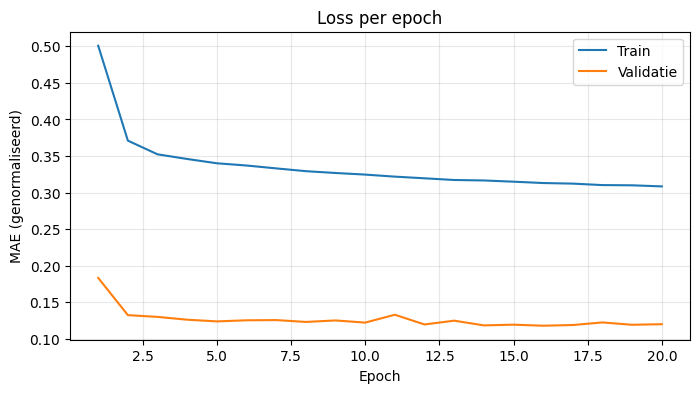

In [13]:
plt.figure(figsize=(8, 4))
plt.plot(range(1, n_epochs + 1), train_loss_list, label='Train')
plt.plot(range(1, n_epochs + 1), val_loss_list, label='Validatie')
plt.xlabel('Epoch')
plt.ylabel('MAE (genormaliseerd)')
plt.title('Loss per epoch')
plt.legend()
plt.grid(alpha=0.3)
plt.show()

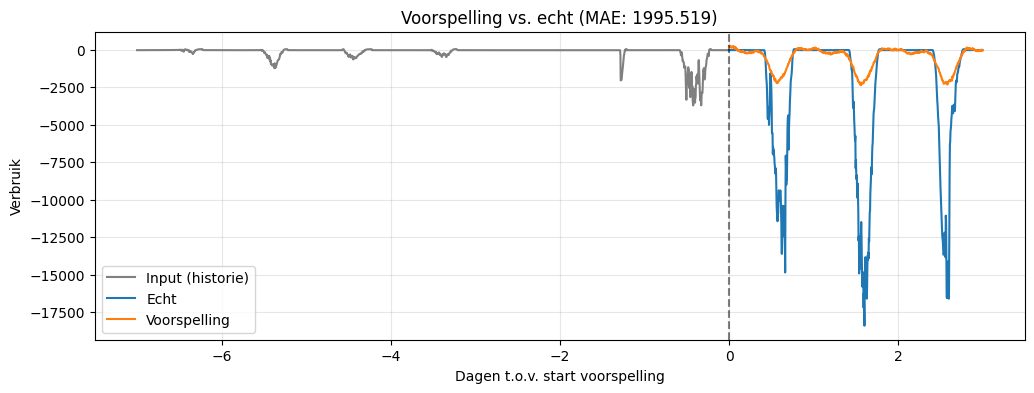

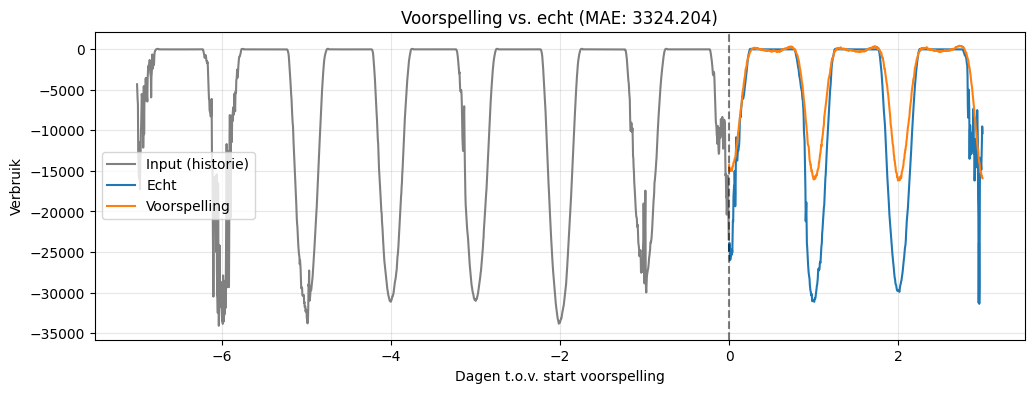

In [14]:
def plot_voorspelling(dataset, idx=0, titel='Voorspelling vs. echt'):
    model.eval()
    x, y = dataset[idx]
    with torch.no_grad():
        pred = model(x.unsqueeze(0).to(DEVICE)).cpu().numpy().flatten()

    # terug naar originele eenheid (de-normaliseren)
    m, s = train_mean[target_idx], train_std[target_idx]
    hist = x[:, target_idx].numpy() * s + m
    echt = y.numpy() * s + m
    pred = pred * s + m

    mae = np.abs(pred - echt).mean()

    t_hist = np.arange(-input_len, 0) / stap_per_dag     # x-as in dagen
    t_fc = np.arange(horizon) / stap_per_dag

    plt.figure(figsize=(12, 4))
    plt.plot(t_hist, hist, color='grey', label='Input (historie)')
    plt.plot(t_fc, echt, label='Echt')
    plt.plot(t_fc, pred, label='Voorspelling')
    plt.axvline(0, color='black', linestyle='--', alpha=0.5)
    plt.xlabel('Dagen t.o.v. start voorspelling')
    plt.ylabel('Verbruik')
    plt.title(f'{titel} (MAE: {mae:.3f})')
    plt.legend()
    plt.grid(alpha=0.3)
    plt.show()

plot_voorspelling(test_dataset, idx=0)
plot_voorspelling(test_dataset, idx=len(test_dataset) // 2)   # een ander moment